# Income Inequality — Which Measure, and Why It Matters

**Artifact class:** `tutorial`  ·  **Data mode:** `empirical`  ·  **Vintage:** ACS 2023 5-Year (pinned)

D01 computed a Gini coefficient and validated it. This notebook asks the question that
follows: **was the Gini the right summary?**

Five standard measures of inequality are computed here from the same distributions. They
weight different parts of the distribution, so they rank the same places differently. The
choice of measure is therefore an analytic decision with consequences — and one that is
almost never disclosed.

> **A note on the title.** This domain was originally named "inequality *and wealth*". The
> ACS cannot measure wealth. Not "imperfectly" — **at all**. The notebook demonstrates
> that against the live variable catalogue rather than asserting it, and names the source
> that can.

Real data only. No synthetic fallback. *Proprietary. SPDX-License-Identifier: LicenseRef-Proprietary*


## Learning Objectives

1. **Compute** five inequality measures — Gini, Theil T, Atkinson at two aversion
   parameters, the p90/p10 ratio, and the top-decile share — from published income
   brackets.
2. **Explain** which region of the distribution each measure is sensitive to, and why
   that makes them disagree.
3. **Quantify** the disagreement: rank correlation between measures, and how far
   individual geographies move between rankings.
4. **Recognise** Lorenz curve crossing — two places with nearly identical Gini
   coefficients and materially different distributions.
5. **State** the normative content of the Atkinson parameter ε, which encodes how much
   weight the analyst places on the bottom of the distribution.
6. **Distinguish** income from wealth, and establish empirically what a data source
   cannot answer before attempting to answer it with that source.


## Prerequisites

**Knowledge.** D01 (Lorenz curves and the Gini). Familiarity with rank correlation.
D03 is useful but not required.

**Setup.** `CENSUS_API_KEY` in the environment or in the file `KRL_SECRETS_PATH` points
at. The data layer reads only the four public-data keys it needs and refuses every other
name before opening the file.

**Packages.** `pandas`, `numpy`, `scipy`, `matplotlib`, and `krl_tutorials_data`.


## Data Provenance

| Variable | Published label (verbatim) | Role |
|---|---|---|
| `B19001_001E` | Estimate!!Total: (households) | bracket universe |
| `B19001_002E`–`B19001_017E` | Household income bracket counts, $0 to $200,000+ | the distribution |
| `B19083_001E` | Estimate!!Gini Index | external check on the Gini only |

All five measures are computed from the **same 16 brackets**. Any disagreement between
them is therefore a property of the measures, not of differing inputs — which is what
makes this a clean comparison.


In [1]:
"""Configuration. The measures are declared here, with what each is sensitive to."""
from __future__ import annotations

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

_here = Path.cwd().resolve()
for _cand in (_here, *_here.parents):
    if (_cand / "src" / "krl_tutorials_data").is_dir():
        sys.path.insert(0, str(_cand / "src")); break
else:
    raise SystemExit("Could not locate krl_tutorials_data from " + str(_here))

from krl_tutorials_data.sources import fetch_acs, DataAccessError, load_key
from krl_tutorials_data.inequality import (
    ACS_B19001_BRACKETS, BracketScheme, lorenz_curve, gini_from_lorenz,
    theil_t, atkinson, percentile_ratio, top_share, open_bracket_share,
    top_share_is_identified, UnidentifiedTopShareError,
)

UNIT_OF_ANALYSIS = "state (50 states + DC + Puerto Rico)"
ACS_VINTAGE = 2023
ATKINSON_EPSILONS = (0.5, 1.5)

# Each measure, and the region of the distribution it responds to most.
MEASURES = {
    "gini":        "whole distribution; most sensitive around the middle",
    "theil_t":     "top-sensitive; responds strongly to concentration at the top",
    "atkinson_0.5": "mildly bottom-weighted (low inequality aversion)",
    "atkinson_1.5": "strongly bottom-weighted (high inequality aversion)",
    "p90_p10":     "ignores everything between the 10th and 90th percentiles",
    "top10_share": "the top decile only; blind to the rest",
}

pd.set_option("display.width", 130)
plt.rcParams["figure.dpi"] = 110

print(f"Unit of analysis : {UNIT_OF_ANALYSIS}")
print(f"Vintage          : ACS {ACS_VINTAGE} 5-Year (pinned)")
print(f"Measures         : {len(MEASURES)}")
for k, v in MEASURES.items():
    print(f"  {k:<14} {v}")

Unit of analysis : state (50 states + DC + Puerto Rico)
Vintage          : ACS 2023 5-Year (pinned)
Measures         : 6
  gini           whole distribution; most sensitive around the middle
  theil_t        top-sensitive; responds strongly to concentration at the top
  atkinson_0.5   mildly bottom-weighted (low inequality aversion)
  atkinson_1.5   strongly bottom-weighted (high inequality aversion)
  p90_p10        ignores everything between the 10th and 90th percentiles
  top10_share    the top decile only; blind to the rest


In [2]:
BRACKETS = {f"B19001_{i:03d}E": f"Households: income bracket {i - 1}" for i in range(2, 18)}
VARIABLES = {
    "B19001_001E": "Estimate!!Total: (households)",
    "B19083_001E": "Estimate!!Gini Index",
    **BRACKETS,
}

try:
    raw, provenance = fetch_acs(
        year=ACS_VINTAGE, variables=VARIABLES, geography="state:*",
        plausible={"B19083_001E": (0.30, 0.60)},
    )
except DataAccessError as exc:
    print("HALTED — real data could not be obtained.")
    print(f"  failure class : {type(exc).__name__}")
    print(f"  detail        : {exc}")
    print("\nNo synthetic fallback exists by design.")
    raise

bracket_cols = list(BRACKETS)
mids = ACS_B19001_BRACKETS.midpoints()
print(f"Retrieved {len(raw)} geographies x {len(bracket_cols)} income brackets.")
print(f"Bracket representative incomes: ${mids[0]:,.0f} ... ${mids[-2]:,.0f}, "
      f"top bracket assumed ${mids[-1]:,.0f}")

Retrieved 52 geographies x 16 income brackets.
Bracket representative incomes: $5,000 ... $175,000, top bracket assumed $350,000


In [3]:
"""Compute every measure from the same brackets."""
rows = []
for _, r in raw.iterrows():
    counts = r[bracket_cols].to_numpy(dtype=float)
    pop, inc = lorenz_curve(counts, mids)
    rows.append({
        "state": r["NAME"],
        "gini": gini_from_lorenz(pop, inc),
        "gini_published": r["B19083_001E"],
        "theil_t": theil_t(counts, mids),
        f"atkinson_{ATKINSON_EPSILONS[0]}": atkinson(counts, mids, epsilon=ATKINSON_EPSILONS[0]),
        f"atkinson_{ATKINSON_EPSILONS[1]}": atkinson(counts, mids, epsilon=ATKINSON_EPSILONS[1]),
        "p90_p10": percentile_ratio(counts, mids, high=0.90, low=0.10),
        # top10_share is only identified when the open top bracket holds less
        # than 10% of households. Where it does not, the whole top decile sits
        # inside one flat bracket and the statistic measures the bracket cap.
        "open_bracket_share": open_bracket_share(counts),
        "top10_identified": top_share_is_identified(counts, top=0.10),
        "top10_share": top_share(counts, mids, top=0.10, allow_unidentified=True),
    })
df = pd.DataFrame(rows)

MEASURE_COLS = ["gini", "theil_t", f"atkinson_{ATKINSON_EPSILONS[0]}",
                f"atkinson_{ATKINSON_EPSILONS[1]}", "p90_p10", "top10_share"]
for m in MEASURE_COLS:
    assert df[m].notna().all(), f"{m} produced missing values."
    assert df[m].var() > 0, f"{m} is constant across geographies."

print("FIVE MEASURES, SAME DISTRIBUTIONS — most unequal by Gini:")
print(df.nlargest(6, "gini")[["state", *MEASURE_COLS]].to_string(
    index=False, float_format=lambda v: f"{v:,.4f}"))
print()
print("Most unequal by the p90/p10 ratio instead:")
print(df.nlargest(6, "p90_p10")[["state", *MEASURE_COLS]].to_string(
    index=False, float_format=lambda v: f"{v:,.4f}"))

FIVE MEASURES, SAME DISTRIBUTIONS — most unequal by Gini:
      state   gini  theil_t  atkinson_0.5  atkinson_1.5  p90_p10  top10_share
Puerto Rico 0.5323   0.5208        0.2348        0.5586  15.6589       0.3862
  Louisiana 0.4905   0.4133        0.2017        0.5520  18.9846       0.3484
Mississippi 0.4802   0.3994        0.1929        0.5264  17.1501       0.3415
 New Mexico 0.4785   0.3939        0.1923        0.5337  16.1446       0.3411
   New York 0.4766   0.3842        0.1958        0.5706  18.8063       0.2865
    Alabama 0.4764   0.3907        0.1902        0.5271  15.0315       0.3411

Most unequal by the p90/p10 ratio instead:
               state   gini  theil_t  atkinson_0.5  atkinson_1.5  p90_p10  top10_share
District of Columbia 0.4549   0.3583        0.1928        0.6128  24.4953       0.2325
           Louisiana 0.4905   0.4133        0.2017        0.5520  18.9846       0.3484
            New York 0.4766   0.3842        0.1958        0.5706  18.8063       0.2865
    

## How much do the measures disagree?

If the measures were interchangeable, ranking by any one of them would give the same
ordering. Spearman rank correlation quantifies how far that is from true. A correlation
below 1 means at least one geography changes position depending on which measure you
chose to report.


### First: is every measure actually identified on this data?

Before comparing rankings, one of the measures has to be checked. The top-decile share is
computed from brackets, and the final bracket is open-ended at `$200,000+`. If **more than
10% of households sit in that bracket**, the entire top decile lies inside it — every
member is assigned the same assumed income, and the statistic can no longer see
concentration within the group it is supposed to describe.

This is not a rounding concern. It inverts the measure.


In [4]:
"""Is the top-decile share even identified here? Check before ranking on it."""
n_bad = int((~df["top10_identified"]).sum())
corr_artifact = df["open_bracket_share"].corr(df["top10_share"])

print("IDENTIFICATION CHECK — top-decile share")
print("=" * 60)
print(f"  geographies where the open $200,000+ bracket holds >= 10% of households: "
      f"{n_bad} of {len(df)}")
print(f"  correlation(open-bracket share, measured top-decile share) = {corr_artifact:+.4f}")
print()
if corr_artifact < -0.5:
    print("  That correlation is the artifact. Where the top decile lies entirely")
    print("  inside the open bracket, every household in it is assigned the same")
    print("  assumed income, so the statistic falls as the genuinely rich share")
    print("  RISES. It is measuring the bracket cap, not the distribution.")
print()
print(df.nlargest(6, "open_bracket_share")[
    ["state", "open_bracket_share", "top10_share", "gini", "top10_identified"]].to_string(
    index=False, float_format=lambda v: f"{v:,.4f}"))
print()

# Restrict every cross-measure comparison to the measures that are identified.
VALID_MEASURES = [m for m in MEASURE_COLS if m != "top10_share"]
df_valid = df[df["top10_identified"]].copy()
print(f"Consequence for this notebook:")
print(f"  - top10_share is EXCLUDED from the cross-measure ranking below.")
print(f"  - it is retained only for the {len(df_valid)} geographies where it is")
print(f"    identified, and shown separately.")
print(f"  - the other {len(VALID_MEASURES)} measures are identified everywhere and are")
print(f"    compared across all {len(df)} geographies.")

IDENTIFICATION CHECK — top-decile share
  geographies where the open $200,000+ bracket holds >= 10% of households: 25 of 52
  correlation(open-bracket share, measured top-decile share) = -0.9521

  That correlation is the artifact. Where the top decile lies entirely
  inside the open bracket, every household in it is assigned the same
  assumed income, so the statistic falls as the genuinely rich share
  RISES. It is measuring the bracket cap, not the distribution.

               state  open_bracket_share  top10_share   gini  top10_identified
District of Columbia              0.2555       0.2325 0.4549             False
       Massachusetts              0.2109       0.2497 0.4527             False
          New Jersey              0.2072       0.2501 0.4472             False
          California              0.1943       0.2592 0.4536             False
            Maryland              0.1917       0.2544 0.4398             False
         Connecticut              0.1822       0.2666 0

In [5]:
"""Rank correlation between measures, and how far individual states move."""
ranks = df[VALID_MEASURES].rank(ascending=False).astype(int)
ranks.insert(0, "state", df["state"])

rho = pd.DataFrame(index=VALID_MEASURES, columns=VALID_MEASURES, dtype=float)
for a in VALID_MEASURES:
    for b in VALID_MEASURES:
        rho.loc[a, b] = stats.spearmanr(df[a], df[b]).statistic

print("SPEARMAN RANK CORRELATION BETWEEN IDENTIFIED MEASURES")
print(f"(top10_share excluded: not identified in {n_bad} of {len(df)} geographies)")
print(rho.to_string(float_format=lambda v: f"{v:,.3f}"))
print()
off = rho.where(~np.eye(len(VALID_MEASURES), dtype=bool))
lo = off.min().min()
pair = off.stack().idxmin()
print(f"Weakest agreement: {pair[0]} vs {pair[1]}  (rho = {lo:.3f})")

spread = (ranks[VALID_MEASURES].max(axis=1) - ranks[VALID_MEASURES].min(axis=1))
ranks["rank_spread"] = spread
n_big = int((spread >= 10).sum())
print()
print(f"Rank spread across measures — how far a state moves depending on the measure:")
print(f"  median spread      : {spread.median():.0f} places")
print(f"  maximum spread     : {spread.max():.0f} places")
print(f"  states moving >= 10 places: {n_big} of {len(df)}")
print()
print("Most measure-dependent geographies:")
print(ranks.nlargest(6, "rank_spread")[["state", *VALID_MEASURES, "rank_spread"]].to_string(index=False))

SPEARMAN RANK CORRELATION BETWEEN IDENTIFIED MEASURES
(top10_share excluded: not identified in 25 of 52 geographies)
              gini  theil_t  atkinson_0.5  atkinson_1.5  p90_p10
gini         1.000    0.989         0.956         0.650    0.712
theil_t      0.989    1.000         0.936         0.578    0.646
atkinson_0.5 0.956    0.936         1.000         0.805    0.845
atkinson_1.5 0.650    0.578         0.805         1.000    0.939
p90_p10      0.712    0.646         0.845         0.939    1.000

Weakest agreement: theil_t vs atkinson_1.5  (rho = 0.578)

Rank spread across measures — how far a state moves depending on the measure:
  median spread      : 11 places
  maximum spread     : 34 places
  states moving >= 10 places: 35 of 52

Most measure-dependent geographies:
               state  gini  theil_t  atkinson_0.5  atkinson_1.5  p90_p10  rank_spread
            Maryland    47       49            39            15       21           34
          New Jersey    37       38      

## Two places, one Gini, different distributions

The Gini compresses an entire distribution into one number, so distributions that differ
in shape can share a Gini. When two Lorenz curves **cross**, neither distribution is
unambiguously more unequal than the other — the answer depends on which part of the
distribution you care about, which is precisely what the Gini hides.


District of Columbia  Gini = 0.4549
Montana  Gini = 0.4544
  difference in Gini                   : 0.00054
  maximum vertical gap between curves  : 0.10831

The same two places under every measure:
               state   gini  theil_t  atkinson_0.5  atkinson_1.5  p90_p10  top10_share
District of Columbia 0.4549   0.3583        0.1928        0.6128  24.4953       0.2325
             Montana 0.4544   0.3549        0.1729        0.4890  11.0015       0.3326


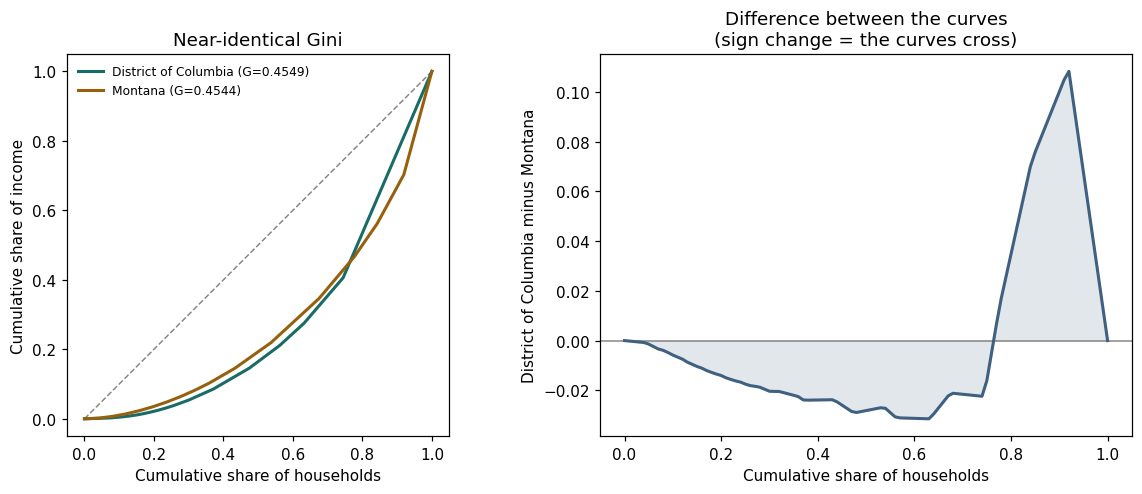

Sign changes in the difference: 3
The curves CROSS. Neither distribution dominates the other, so no single
scalar measure can order them without embedding a value judgement.


In [6]:
"""Find the pair with the closest Gini values but the most divergent Lorenz curves."""
curves = {}
for _, r in raw.iterrows():
    counts = r[bracket_cols].to_numpy(dtype=float)
    curves[r["NAME"]] = lorenz_curve(counts, mids)

gmap = dict(zip(df["state"], df["gini"]))
grid = np.linspace(0, 1, 101)

best = None
names = list(curves)
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        a, b = names[i], names[j]
        dg = abs(gmap[a] - gmap[b])
        if dg > 0.002:          # require near-identical Gini
            continue
        ia = np.interp(grid, curves[a][0], curves[a][1])
        ib = np.interp(grid, curves[b][0], curves[b][1])
        divergence = float(np.abs(ia - ib).max())
        if best is None or divergence > best["divergence"]:
            best = {"a": a, "b": b, "gini_gap": dg, "divergence": divergence}

if best is None:
    print("No pair with Gini within 0.002 was found in this vintage.")
else:
    a, b = best["a"], best["b"]
    print(f"{a}  Gini = {gmap[a]:.4f}")
    print(f"{b}  Gini = {gmap[b]:.4f}")
    print(f"  difference in Gini                   : {best['gini_gap']:.5f}")
    print(f"  maximum vertical gap between curves  : {best['divergence']:.5f}")
    print()
    cmp = df[df["state"].isin([a, b])][["state", *MEASURE_COLS]]
    print("The same two places under every measure:")
    print(cmp.to_string(index=False, float_format=lambda v: f"{v:,.4f}"))

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
    axes[0].plot([0, 1], [0, 1], "--", lw=1, color="#888")
    for nm, col in ((a, "#186b66"), (b, "#96600c")):
        axes[0].plot(*curves[nm], lw=2, color=col, label=f"{nm} (G={gmap[nm]:.4f})")
    axes[0].set_xlabel("Cumulative share of households")
    axes[0].set_ylabel("Cumulative share of income")
    axes[0].set_title("Near-identical Gini")
    axes[0].legend(loc="upper left", frameon=False, fontsize=8)
    axes[0].set_aspect("equal")

    ia = np.interp(grid, curves[a][0], curves[a][1])
    ib = np.interp(grid, curves[b][0], curves[b][1])
    axes[1].axhline(0, color="#888", lw=1)
    axes[1].plot(grid, ia - ib, lw=2, color="#3f6081")
    axes[1].fill_between(grid, ia - ib, alpha=0.15, color="#3f6081")
    axes[1].set_xlabel("Cumulative share of households")
    axes[1].set_ylabel(f"{a} minus {b}")
    axes[1].set_title("Difference between the curves\n(sign change = the curves cross)")
    plt.tight_layout(); plt.show()

    crossings = int((np.diff(np.sign(ia - ib)) != 0).sum())
    print(f"Sign changes in the difference: {crossings}")
    if crossings > 1:
        print("The curves CROSS. Neither distribution dominates the other, so no single")
        print("scalar measure can order them without embedding a value judgement.")

## Which measures are most fragile?

D01 showed that the assumed mean of the open top bracket moves the Gini. It does not move
every measure equally: top-sensitive measures are hit hardest, and measures that ignore
the top are nearly immune. That difference is itself useful information when choosing one.


In [7]:
"""Sensitivity of each measure to the open top-bracket assumption."""
sens = []
for top_mean in (250_000, 350_000, 450_000, 600_000):
    scheme = BracketScheme(edges=ACS_B19001_BRACKETS.edges, top_mean=float(top_mean),
                           top_mean_basis="sensitivity sweep")
    m = scheme.midpoints()
    vals = {"assumed_top_mean": top_mean}
    acc = {k: [] for k in MEASURE_COLS}
    for _, r in raw.iterrows():
        counts = r[bracket_cols].to_numpy(dtype=float)
        pop, inc = lorenz_curve(counts, m)
        acc["gini"].append(gini_from_lorenz(pop, inc))
        acc["theil_t"].append(theil_t(counts, m))
        acc[f"atkinson_{ATKINSON_EPSILONS[0]}"].append(atkinson(counts, m, epsilon=ATKINSON_EPSILONS[0]))
        acc[f"atkinson_{ATKINSON_EPSILONS[1]}"].append(atkinson(counts, m, epsilon=ATKINSON_EPSILONS[1]))
        acc["p90_p10"].append(percentile_ratio(counts, m))
        # Sweep only: this measures how the statistic RESPONDS to the top-bracket
        # assumption, which is exactly the question for geographies where it is
        # unidentified. It is not used for any ranking claim, so the limitation
        # is acknowledged rather than avoided.
        acc["top10_share"].append(top_share(counts, m, allow_unidentified=True))
    vals.update({k: float(np.mean(v)) for k, v in acc.items()})
    sens.append(vals)
sdf = pd.DataFrame(sens)

print("MEAN VALUE OF EACH MEASURE ACROSS THE TOP-BRACKET SWEEP")
print(sdf.to_string(index=False, float_format=lambda v: f"{v:,.4f}"))
print()
rel = ((sdf[MEASURE_COLS].max() - sdf[MEASURE_COLS].min()) / sdf[MEASURE_COLS].mean())
print("Relative sensitivity (range / mean), most fragile first:")
for k, v in rel.sort_values(ascending=False).items():
    print(f"  {k:<16} {v:.1%}   [{MEASURES[k]}]")
print()
print()
print("Note: top10_share appears here because the sweep asks how each statistic")
print("RESPONDS to the assumption. It is still excluded from every ranking claim")
print("in this notebook, for the identification reason established above.")

MEAN VALUE OF EACH MEASURE ACROSS THE TOP-BRACKET SWEEP
 assumed_top_mean   gini  theil_t  atkinson_0.5  atkinson_1.5  p90_p10  top10_share
           250000 0.4094   0.2779        0.1455        0.4663  12.1650       0.2567
           350000 0.4569   0.3576        0.1774        0.5124  12.9980       0.3139
           450000 0.4955   0.4393        0.2084        0.5522  13.8310       0.3607
           600000 0.5415   0.5555        0.2509        0.6014  15.0805       0.4172

Relative sensitivity (range / mean), most fragile first:
  theil_t          68.1%   [top-sensitive; responds strongly to concentration at the top]
  atkinson_0.5     53.9%   [mildly bottom-weighted (low inequality aversion)]
  top10_share      47.6%   [the top decile only; blind to the rest]
  gini             27.8%   [whole distribution; most sensitive around the middle]
  atkinson_1.5     25.3%   [strongly bottom-weighted (high inequality aversion)]
  p90_p10          21.6%   [ignores everything between the 10th and

## What this data cannot see

The domain this notebook replaces was named "inequality **and wealth**". Income and wealth
are different quantities: income is a flow over a year, wealth is a stock accumulated over
a lifetime and across generations. They are distributed differently, and a finding about
one is not a finding about the other.

Rather than assert that the ACS cannot measure wealth, the cell below establishes it
against the live variable catalogue.


In [8]:
"""Establish empirically what this source does not contain, before claiming anything."""
import requests

cat = requests.get(f"https://api.census.gov/data/{ACS_VINTAGE}/acs/acs5/groups.json",
                   timeout=60)
if cat.status_code != 200 or "json" not in (cat.headers.get("content-type") or ""):
    raise RuntimeError(f"Variable catalogue unavailable: HTTP {cat.status_code}")
groups = cat.json()["groups"]

CONCEPTS = ["WEALTH", "NET WORTH", "ASSET", "DEBT", "SAVINGS", "PORTFOLIO", "INHERITANCE"]
print(f"ACS {ACS_VINTAGE} 5-Year publishes {len(groups):,} tables.\n")
for term in CONCEPTS:
    hits = [g for g in groups if term in (g.get("description") or "").upper()]
    print(f"  tables whose concept mentions {term!r:<14}: {len(hits)}")
income_tables = [g for g in groups if "INCOME" in (g.get("description") or "").upper()]
print(f"  tables whose concept mentions 'INCOME'{'':<9}: {len(income_tables)}")
print()
print("The ACS asks about income. It asks no question about assets, debts or net")
print("worth, so no amount of processing recovers wealth from it. The source that")
print("can is the Federal Reserve's Survey of Consumer Finances (SCF) — triennial,")
print("national only, released as bulk microdata rather than an API, and therefore")
print("outside this notebook's scope. A state-level wealth Gini is not available")
print("from any public source at this cadence.")

ACS 2023 5-Year publishes 1,193 tables.

  tables whose concept mentions 'WEALTH'      : 0
  tables whose concept mentions 'NET WORTH'   : 0
  tables whose concept mentions 'ASSET'       : 0
  tables whose concept mentions 'DEBT'        : 0
  tables whose concept mentions 'SAVINGS'     : 0
  tables whose concept mentions 'PORTFOLIO'   : 0
  tables whose concept mentions 'INHERITANCE' : 0
  tables whose concept mentions 'INCOME'         : 195

The ACS asks about income. It asks no question about assets, debts or net
worth, so no amount of processing recovers wealth from it. The source that
can is the Federal Reserve's Survey of Consumer Finances (SCF) — triennial,
national only, released as bulk microdata rather than an API, and therefore
outside this notebook's scope. A state-level wealth Gini is not available
from any public source at this cadence.


## Limitations

1. **The top-decile share is not identified for half these geographies**, because the
   open `$200,000+` bracket holds 10% or more of households in 25 of 52. It is excluded
   from the cross-measure comparison and reported only where identified. A tutorial that
   ranked states on the unguarded statistic would have published an artifact whose
   correlation with the open-bracket share is about -0.95.
2. **All measures inherit the bracket assumptions.** Within-bracket uniformity and the
   assumed open-top mean affect every figure here; the sweep above quantifies how much,
   per measure.
3. **Survey uncertainty is not propagated to these measures.** D03 develops margin-of-error
   propagation for a derived percentage. Doing the same for a Gini or a Theil index
   requires replicate weights the public API does not expose, so the rankings here carry
   sampling uncertainty that is real and unquantified. Treat small differences as noise.
4. **ε is a value judgement, not an estimate.** The Atkinson results depend on a parameter
   chosen by the analyst. Two defensible analysts may pick differently and reach different
   conclusions from the same data. That is the measure working as designed, not a defect.
5. **Income, not wealth** — established empirically above, and worth restating because the
   two are routinely conflated in commentary.
6. **Pre-tax, pre-transfer money income.** ACS income excludes capital gains and non-cash
   benefits (SNAP, Medicaid, housing assistance) and is measured before taxes. Measures of
   post-tax, post-transfer inequality are substantially lower and tell a different story.
7. **Cross-sectional.** One vintage. Nothing here speaks to whether inequality is rising
   or falling.


## Key Takeaways

- **The measure is a choice, and the choice shows.** Five measures of the same
  distributions produce different rankings. Reporting one without naming the alternatives
  presents a decision as though it were an observation.
- **Each measure is sensitive to a different region.** Theil responds to the top, Atkinson
  at high ε to the bottom, p90/p10 to neither middle nor tails. Match the measure to the
  question rather than to convention.
- **Lorenz curves can cross.** When they do, no scalar summary can order the two
  distributions without embedding a value judgement about which part matters.
- **Atkinson's ε is normative.** An Atkinson index quoted without its ε is not
  interpretable.
- **Robustness is a selection criterion.** The sweep shows which measures survive the
  top-bracket assumption and which do not.
- **Check what a source cannot answer before using it.** The ACS has 195 income tables and
  zero wealth tables. Establishing that took one request; assuming otherwise would have
  produced a notebook about a quantity the data never contained.
- **Check that a measure is identified before you rank on it.** The top-decile share looks
  perfectly well-behaved on this data — it returns a plausible number for every state — and
  is meaningless for half of them. The check costs one line; omitting it would have
  produced a confident, inverted ranking.


## Exercises

1. **Change the question, change the measure.** For each of these, argue which measure is
   most appropriate and why: (a) targeting anti-poverty transfers, (b) assessing whether
   top incomes have pulled away, (c) comparing two countries for a policy brief.
2. **Make the crossing bite.** Take the crossing pair found above and compute, for each,
   the income share of the bottom quintile and of the top ventile. Which place would you
   rather be poor in, and which measure would have told you?
3. **Sweep ε.** Compute the Atkinson index for ε from 0.1 to 3.0 for the five most unequal
   states. At what ε does the ordering change, and what would you have to believe about
   social welfare for that ε to be the right one?
4. **Break the top bracket.** Re-run the sensitivity sweep with an assumed top mean of
   $1,000,000. Which measures still rank states the same way, and which have reordered?
5. **Propagate the uncertainty.** Using D03's tooling, bootstrap the bracket counts within
   their margins of error and produce a confidence interval for one state's Gini. Does it
   overlap its neighbours?
6. **Go find the wealth data.** Download the SCF summary extract. What is the smallest
   geography it supports, and what does that imply for any state-level claim about wealth
   inequality you have read recently?
7. **Recover the top share honestly.** For a state where the top decile is unidentified,
   find a `top` fraction that *is* identified and compute that share instead. What is the
   smallest group you can resolve, and what does that tell you about the resolution limit
   of bracketed public data?


## References

1. **U.S. Census Bureau.** *American Community Survey 5-Year Estimates, 2023*, tables
   B19001 and B19083.
2. **Atkinson, A. B.** (1970). "On the measurement of inequality." *Journal of Economic
   Theory*, 2(3), 244–263. — the inequality-aversion parameter.
3. **Theil, H.** (1967). *Economics and Information Theory.* North-Holland. — the Theil index.
4. **Cowell, F. A.** (2011). *Measuring Inequality*, 3rd ed. Oxford University Press. —
   the standard treatment of why measures disagree.
5. **Sen, A.** (1997). *On Economic Inequality*, expanded ed. Clarendon Press. — the
   normative content of inequality measurement.
6. **Board of Governors of the Federal Reserve System.** *Survey of Consumer Finances.*
   <https://www.federalreserve.gov/econres/scfindex.htm> — the wealth source the ACS is not.
